# Discrete Fourier Transform (DFT)

The notebook consists of two parts:
- The first part (Part 0) is a demonstration of the use of the DFT (_you read and execute the code cells_),
- The second part is a simple exercise with the DFT (_you write the code_).

> **Note the use of zip, stem, annotate and the modulo operator:**
>
> Refer to PA 2.3 if you do not understand these tools. Furthermore, note that the term _modulus_ (in relation to complex numbers) is also used here (and in the textbook), which is another term for _absolute value._

In [1]:
import numpy as np
from matplotlib import pyplot as plt

## Part 0: Demonstration of DFT using pulse function

In the first part of this notebook, we use  $x(t)=\Pi(\frac{t}{4})$, and its Fourier transform $X(f)=4 \,\textrm{sinc}(4f)$, as an example (see the first worked example in Section 3 on the Fourier transform, in the chapter on Signal processing). The pulse lasts for 4 seconds in the time domain; for convenience, below it is not centered at $t$ = 0, but shifted (delayed) to the right.

The signal $x(t)$ clearly is non-periodic and is an energy signal; apart from a short time span of 'activity' it is zero elsewhere.

We create a pulse function $x(t)$ in discrete time $x_n$ by numpy. The total signal duration is $T$ = 20 seconds (observation or record length). The sampling interval is $\Delta t$ = 1 second. There are $N$ = 20 samples, and each sample represents 1 second, hence $N \Delta t = T$.

Note that the time array starts at $t$ = 0 s, and hence, the last sample is at $t$ = 19 s (and not at $t$ = 20 s, as then we would have 21 samples).

### Part 0.1: Visualize the Signal

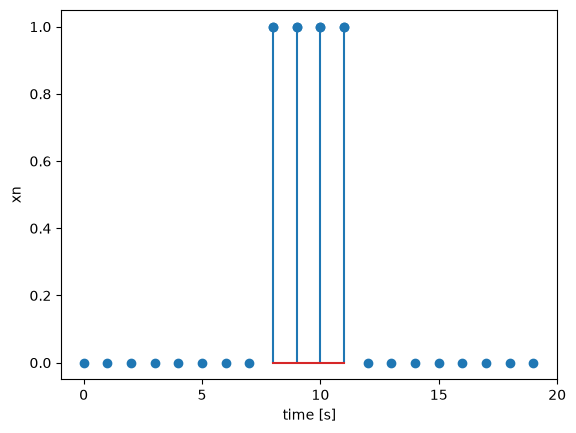

In [7]:
t = np.arange(0,20,1)
xt = np.concatenate((np.zeros(8), np.ones(4), np.zeros(8)))

plt.plot(t, xt,'o')
plt.stem(t[8:12], xt[8:12]) 
plt.xticks(ticks=np.arange(0,21,5), labels=np.arange(0,21,5))
plt.xlabel('time [s]')
plt.ylabel('xn');

### Part 0.2: Evaluate (and visualize) the DFT

We use `numpy.fft.fft` to compute the one-dimensional Discrete Fourier Transform (DFT) of $x_n$, which takes a signal as argument and returns an array of coefficients (refer to the [documentation](https://numpy.org/doc/stable/reference/generated/numpy.fft.fft.html) as needed).

The DFT converts $N$ samples of the time domain signal $x_n$, into $N$ samples of the frequency domain. In this case, it produces $X_k$ with $k = 0, 1, 2, \ldots, N-1$, with $N$ = 20, which are complex numbers. 

> **Task 0.2:**
>
> Read the code cell below before executing it and identify the following:
>
> - Where is the DFT computed, and what is the output?
>
> - Why is the modulus (absolute value) used on the DFT output?
>
> - What values are used for the x and y axes of the plot?
>
> - How is frequency information found and added to the plot (mathematically)?
>
> Once you understand the figure, continue reading to understand what do these 20 complex numbers mean, and how should we interpret them?

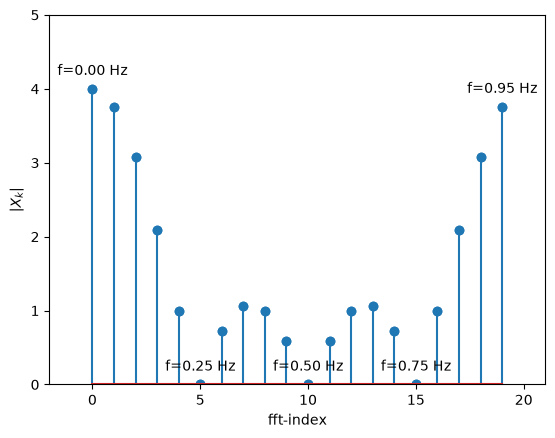

In [9]:
abs_fft = np.abs(np.fft.fft(xt))
index_fft = np.arange(0,20,1)
plt.plot(index_fft, abs_fft, 'o')

freq = np.arange(0, 1, 0.05)
for x,y in zip(index_fft, abs_fft):
    if x%5 == 0 or x==19:
        label = f"f={freq[x]:.2f} Hz"
        plt.annotate(label, 
                     (x,y),
                     textcoords="offset points", 
                     xytext=(0,10),
                     fontsize=10,
                     ha='center') 
plt.ylim(0,5)
plt.xlim(-2,21)
plt.xlabel('fft-index')
plt.ylabel('$|X_k|$')
plt.stem(index_fft, abs_fft);

The frequency resolution $\Delta f$ equals one-over-the-measurement-duration, hence $\Delta f = 1/T$. With that knowledge, we can reconstruct the frequencies expressed in Hertz.

The spectrum of the sampled signal is periodic in the sampling frequency $f_s$ which equals 1 Hz ($\Delta t$ = 1 s). Therefore, it is computed just for one period $[0,f_s)$. The last value, with index 19, represents the component with frequency $f$ = 0.95 Hz. A spectrum is commonly presented and interpreted as double-sided, so in the above graph we can interpret the spectral components with indices 10 to 19 corresponding to negative frequencies. 

### Part 0.3: Identify the negative frequencies

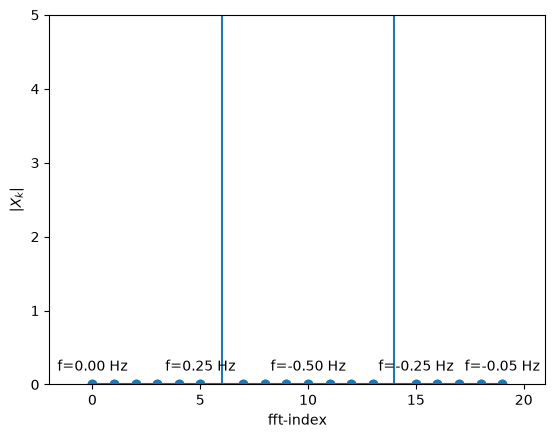

In [ ]:
abs_fft = np.abs(np.fft.fft(xt))
plt.stem(index_fft, abs_fft)
plt.plot(index_fft, abs_fft, 'o')

freq = np.concatenate((np.arange(0, 0.5, 0.05), np.arange(-0.5, 0, 0.05)))
for x,y in zip(index_fft, abs_fft):
    if x%5 == 0 or x==19:
        label = f"f={freq[x]:.2f} Hz"
        plt.annotate(label, 
                     (x,y),
                     textcoords="offset points", 
                     xytext=(0,10),
                     fontsize=10,
                     ha='center') 
plt.ylim(0,5)
plt.xlim(-2,21)
plt.xlabel('fft-index')
plt.ylabel('$|X_k|$');

Now we can interpret the DFT of the $x(t)=\Pi(\frac{t}{4})$. The sampling interval is $\Delta t$ = 1 second, and the observation length is T=20 seconds, and we have N=20 samples.  
- We can recognize a bit of a sinc function.
- The DFT is computed from 0 Hz, for positive frequencies up to $\frac{fs}{2} = 0.5$ Hz, after which the negative frequencies follow from -0.5 to -0.05 Hz.
- $X(f)=4 \textrm{sinc}(4f)$ has its first null at $f=0.25$Hz.

### Part 0.4: Create symmetric plot

For convenient visualization, we may want to explicitly shift the negative frequencies to the left-hand side to create a symmetric plot. We can use `numpy.fft.fftshift` to do that. In other words, the zero-frequency component appears in the center of the spectrum. Now, it nicely shows a symmetric sprectrum. It well resembles the sinc-function (taking into account that we plot the modulus/absolute value). The output of the DFT still consists of $N$ = 20 elements. To enable this, we set up a new frequency array (in Hz) on the interval $[-fs/2,fs/2)$.

> **Task 0.4:**
>
> Read the code cell below before executing it and identify how the plot is modified based on the (new) specification of frequency. Note that it is more than just the freq variable!

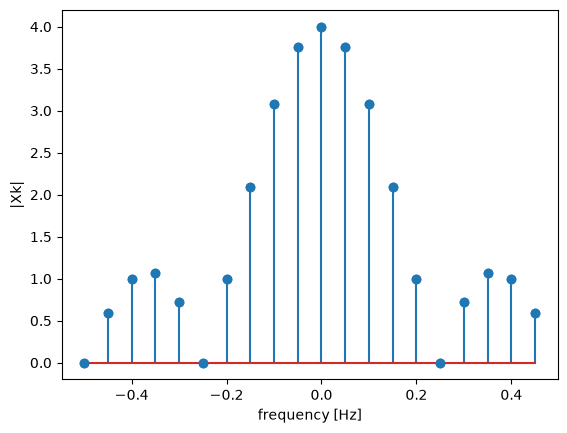

In [11]:
abs_fft_shift = np.abs(np.fft.fftshift(np.fft.fft(xt)))
freq = np.arange(-0.5, 0.5, 0.05)
plt.stem(freq, abs_fft_shift)
plt.plot(freq, abs_fft_shift, 'o')
plt.ylabel('|Xk|')
plt.xlabel('frequency [Hz]');

### Part 0.5: Showing spectrum only for positive frequencies

In practice, because of the symmetry, one typically plots only the right-hand side of the (double-sided) spectrum, hence only the part for positive frequencies $f \geq 0$. This is simply a matter of preference, and a way to save some space.

> **Task 0.5:**
>
> Can you identify what has changed (in the code and visually), compared to the previous plot?

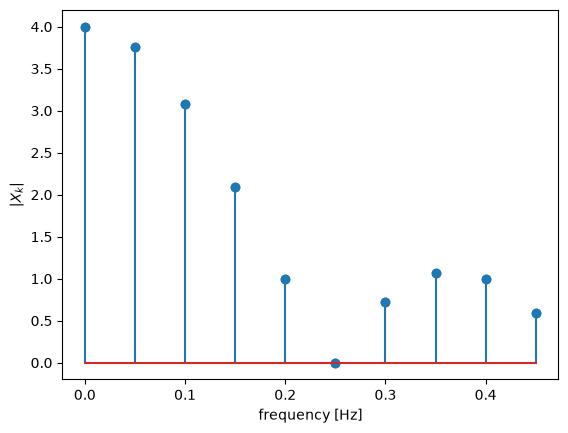

In [12]:
N=len(xt)
abs_fft = np.abs(np.fft.fft(xt))
freq = np.arange(0.0, 1.0, 0.05)
plt.plot(freq[:int((N+1)/2)], abs_fft[:int((N+1)/2)], 'o')
plt.stem(freq[:int((N+1)/2)], abs_fft[:int((N+1)/2)])
plt.ylabel('$|X_k|$')
plt.xlabel('frequency [Hz]');

> **Task 0.6:**
>
> Confirm that you understand how we have arrived at the plot above, which illustrates the magnitude (amplitude) spectrum for frequencies $f \in [0,f_s/2)$, rather than $[0,f_s)$.

## Part 1: Application of DFT using simple cosine

It is always a good idea, in spectral analysis, to run a test with a very simple, basic signal. In this way you can test and verify your coding and interpretation of the results. 

Our basic signal is just a plain cosine. We take the amplitude equal to one, and zero initial phase, so the signal reads $x(t) = \cos(2 \pi f_c t)$, with $f_c$ = 3 Hz in this exercise. With such a simple signal, we know in advance how the spectrum should look like. Namely just a spike at $f$ = 3 Hz, and also one at $f$ = -3 Hz, as we're, for mathematical convenience, working with double sided spectra. The spectrum should be zero at all other frequencies.

As a side note: the cosine is strictly a periodic function, not a-periodic (as above); still, the Fourier transform of the cosine is defined as two Dirac delta pulses or peaks (at 3 Hz and -3 Hz). You may want to check out the second worked example in Section 3 on the Fourier transform: Fourier transform in the limit.

> **Task 1:**
>
> Create a sampled (discrete time) cosine signal by sampling at $f_s$ = 10 Hz, for a duration of $T$ = 2 seconds (make sure you use exactly $N$ = 20 samples). Plot the sampled signal, compute its DFT and plot its magnitude spectrum $|X_k|$ with proper labeling of the axes (just like we did in the part 0 of this notebook). Include a plot of the spectrum of the sampled cosine signal using only the positive frequencies (up to $f_s/2$, as in the last plot of the previous task).
>
> Note: you are expected to produce three separate plots.

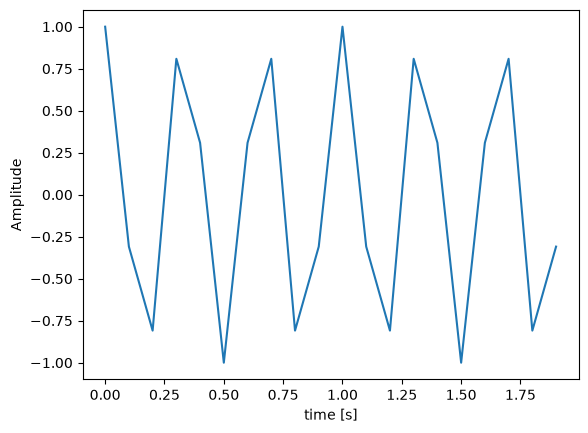

In [82]:
### YOUR CODE HERE ###
N = 20
T = 2
fs = 10 # Hz
fc = 3 # Hz

t = np.arange(0,T,T/N)

xt = np.cos(2 * np.pi * fc * t)

# Plot 1
# plt.stem(t,xt)
plt.plot(t,xt)
plt.xlabel('time [s]')
plt.ylabel('Amplitude')
plt.show()


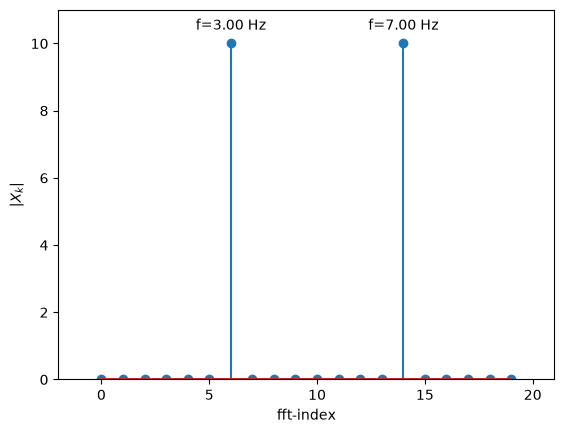

In [87]:
### YOUR CODE HERE ###
abs_fft = np.abs(np.fft.fft(xt))
index_fft = np.arange(0,N,1)

# Plot 2
# plt.plot(index_fft, abs_fft, 'o')

freq = np.linspace(0, fs - (1 / T), N)
for x,y in zip(index_fft, abs_fft):
    if x == 6 or x == N - 6:
        label = f"f={freq[x]:.2f} Hz"
        plt.annotate(label, 
                     (x,y),
                     textcoords="offset points", 
                     xytext=(0,10),
                     fontsize=10,
                     ha='center') 
plt.ylim(0,np.max(abs_fft)+1)
plt.xlim(-2,N+1)
plt.xlabel('fft-index')
plt.ylabel('$|X_k|$')
plt.stem(index_fft, abs_fft);

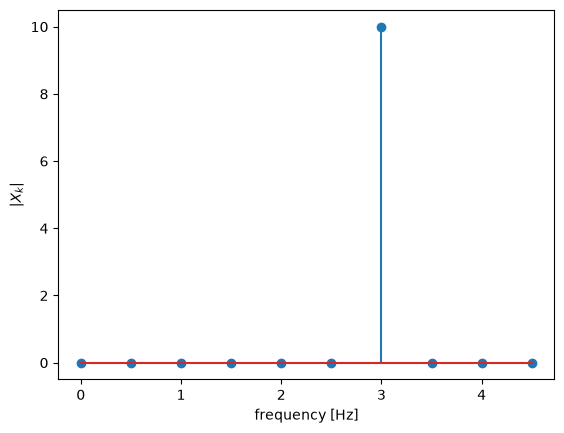

In [81]:
### YOUR CODE HERE ###
# Plot 3
# plt.plot(freq[:int((N+1)/2)], abs_fft[:int((N+1)/2)], 'o')
plt.stem(freq[:int((N+1)/2)], abs_fft[:int((N+1)/2)])
plt.ylabel('$|X_k|$')
plt.xlabel('frequency [Hz]');

> By Christian Tiberius, Delft University of Technology. CC BY 4.0, more info [on the Credits page of Workbook](https://mude.citg.tudelft.nl/workbook-2026/credits.html).